# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using Turing
using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [2]:
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")

restructDatInfAllo (generic function with 1 method)

# Extract Data in Stan Format

In [3]:
mainpath = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\";
paths = [mainpath*"4Mil_Dat.csv", mainpath*"4Mil_12-8mMPyr_Dat.csv"]

2-element Vector{String}:
 "C:\\IBECPostDocDrive\\2024_01_16_" ⋯ 26 bytes ⋯ "ence\\ProcessedData\\4Mil_Dat.csv"
 "C:\\IBECPostDocDrive\\2024_01_16_" ⋯ 36 bytes ⋯ "ssedData\\4Mil_12-8mMPyr_Dat.csv"

In [4]:
dat = restructDatInfAllo(paths, 7.363810535539445)

Dict{String, Any} with 14 entries:
  "Means"  => [7114.49 34670.7; 5374.68 24694.2; … ; -1.15072 40.1292; 0.143625…
  "stsl"   => [78 77]
  "obSta"  => [1 2]
  "sts"    => [0 0; 15 20; … ; 390 395; 395 0]
  "obser"  => 2
  "Y0us"   => [3204.17 15614.7; 0.0 0.0; … ; 0.0 0.0; 7114.49 34670.7]
  "ts"     => [1.0e-20 1.0e-20; 1.0 1.0; … ; 394.0 394.0; 395.0 395.0]
  "itp"    => [0.0, 0.0]
  "ncells" => [4 4]
  "stslm"  => 78
  "tml"    => 396
  "Erros"  => [706.515 833.266; 455.928 727.542; … ; 3.06334 2.76882; 4.51173 3…
  "m"      => 2
  "nts"    => [395 395]

In [5]:
dat["Y0us"]

12×2 Matrix{Float64}:
 3204.17     15614.7
    0.0          0.0
    0.0          0.0
    7.36381      7.36381
    0.0          0.0
    0.0          0.0
    0.0          0.0
    0.0          0.0
    0.0          0.0
 3204.17     15614.7
    0.0          0.0
 7114.49     34670.7

# Bayesian Inference

In [7]:
modelpath = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\HP_PyrLac_AllostericModel.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrAllosteric", model=Model, nchains =4,
            num_samples  = 500, num_warmup = 750, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;

In [8]:
rc, chns, cnames = stan(StanModel, dat)#, init = ini) 
# Runs in about 35 min


Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: CVode(cvodes_mem, t_final, nv_state_, &t_init, CV_NORMAL) failed with error flag -3: 
Error test failures occurred too many times during one internal time step or minimum step size was reached. (in 'c:/IBECPostDocDrive/2024_01_16_NCvsKR/DataProcessingInference/BayesianInference/tmp/PyrAllosteric.stan', line 189, column 6 to column 135)
If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: CVode(cvodes_mem, t_final, nv_state_, &t_init, CV_NORMAL) failed with error flag -3: 
Error test failures occurred too many times during one internal time step or minimum step s

In [12]:
using JLD2

In [ ]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\Results\\PyrAllostericInferRes.jld", "rc", rc, "chns", chns, "cnames", cnames)

In [ ]:
poster = vcat(chns[1001:end, end-4:end, 1], chns[1001:end, end-4:end, 2], chns[1001:end, end-4:end, 3], chns[1001:end, end-4:end, 4])
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\Results\\PosteriorAllosteric.jld", "poster", poster)
CSV.write("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\Results\\PosteriorAllosteric.csv", DataFrame(poster, :auto))

In [5]:
poster = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\Results\\PosteriorAllosteric.csv", DataFrame))

8000×5 Matrix{Float64}:
 0.0121071   0.00729403  51.4335  40.9982  0.000437063
 0.0116509   0.00723133  51.3631  41.0411  0.00044108
 0.0123224   0.00547302  51.4221  39.987   0.000404548
 0.0126204   0.00534944  51.3858  40.1811  0.000404335
 0.0106319   0.00763115  51.2069  40.5615  0.00048387
 0.0106507   0.00658548  51.1339  40.0669  0.000455157
 0.0105514   0.0064369   51.1157  39.9787  0.000465196
 0.0109566   0.00758906  51.242   41.9763  0.000453411
 0.0117418   0.00738684  51.1486  41.2011  0.000449053
 0.00993475  0.00791581  51.3677  40.5013  0.000500054
 ⋮                                         
 0.0128396   0.00628302  51.1818  41.2065  0.00040296
 0.0118199   0.00576482  51.1894  41.1471  0.000414567
 0.0113666   0.00618741  51.3667  39.7863  0.00043711
 0.0124957   0.00535189  51.1049  41.7513  0.000388978
 0.0133171   0.00604009  51.1365  42.3193  0.000387134
 0.0132059   0.00541543  50.8826  41.7596  0.000385359
 0.0148804   0.00485789  51.3463  41.1598  0.000360335
 

# Plot Posteriors Against Priors

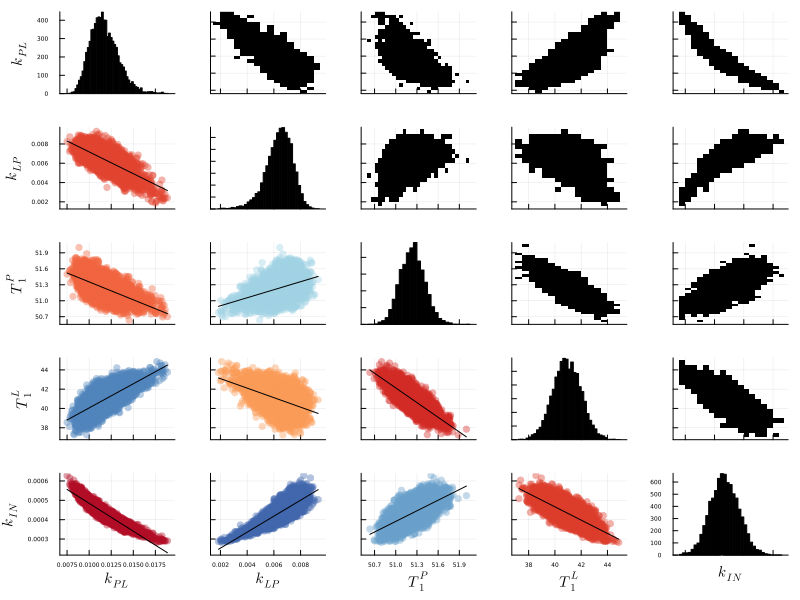

In [24]:
pc = corrplot(poster, label = [L"k_{PL}",L"k_{LP}",L"T_1^P",L"T_1^L",L"k_{IN}"])

fp1 = plot(pc, size=(800,600), xtickfont=font(4), ytickfont=font(4), guidefont=font(10))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SVGsInit\\PosteriorAllostericCorr.svg")
savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SVGsInit\\PosteriorAllostericCorr.png")

display(fp1)

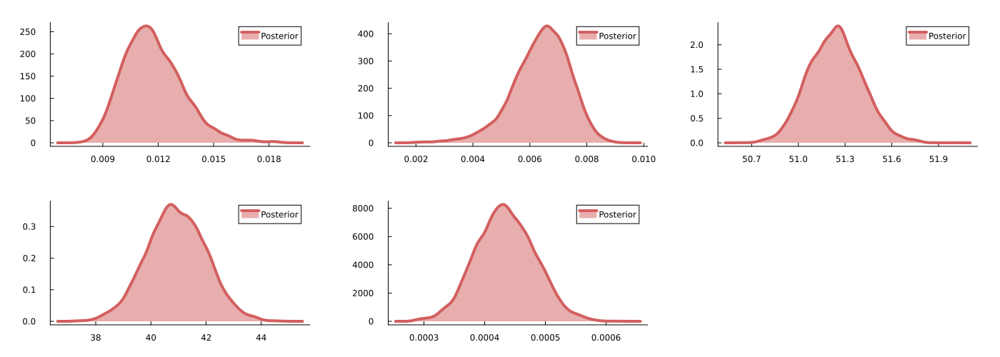

In [8]:
p1 = plot(kde(poster[:,1]), label = "Posterior", linewidth = 4, color = "#d35f5fff", fill=(0, .5))

p2 = plot(kde(poster[:,2]), label = "Posterior", linewidth = 4, color = "#d35f5fff", fill=(0, .5))

p3 = plot(kde(poster[:,3]), label = "Posterior", linewidth = 4, color = "#d35f5fff", fill=(0, .5))

p4 = plot(kde(poster[:,4]), label = "Posterior", linewidth = 4, color = "#d35f5fff", fill=(0, .5))

p5 = plot(kde(poster[:,5]), label = "Posterior", linewidth = 4, color = "#d35f5fff", fill=(0, .5))


plot(p1,p2,p3,p4, p5, size = (1400,500), margin = 6mm, grid=false)

# savefig("PosteriorTest.svg")

plot(p1,p2,p3,p4, p5, size = (1400,500), margin = 6mm, grid=false)


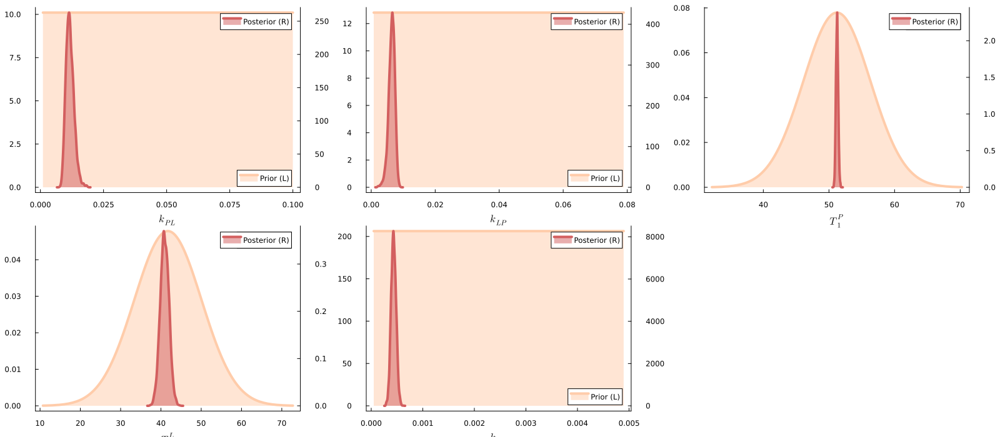

In [9]:
pp = [0.00999999999989405
0.00789216686370161
51.20933014343426
41.73351464475684
0.0004895619448586228];

p1 = plot(Uniform(0.0009999, 0.09999), label = "Prior (L)", xlabel = L"k_{PL}", linewidth = 4, color = "#ffccaaff", fill=(0, .5))
plot!(twinx(), kde(poster[:,1]), label = "Posterior (R)", linewidth = 4, color = "#d35f5fff", fill=(0, .5))
# plot!(twinx(), [pp[1], pp[1]],[0,maximum(kde(poster[:,1]).density)], linewidth=3)


p2 = plot(Uniform(0.000789, 0.0789), label = "Prior (L)", xlabel = L"k_{LP}", linewidth = 4, color = "#ffccaaff", fill=(0, .5))
plot!(twinx(), kde(poster[:,2]), label = "Posterior (R)", linewidth = 4, color = "#d35f5fff", fill=(0, .5))
# plot!(twinx(), [pp[2], pp[2]],[0,maximum(kde(poster[:,1]).density)], linewidth=3)

p3 = plot(Normal(51.21, 5.12), label = "Prior (L)", xlabel = L"T_1^P", linewidth = 4, color = "#ffccaaff", fill=(0, .5))
plot!(twinx(), kde(poster[:,3]), label = "Posterior (R)", linewidth = 4, color = "#d35f5fff", fill=(0, .5))
# plot!(twinx(), [pp[3], pp[3]],[0,maximum(kde(poster[:,1]).density)], linewidth=3)

p4 = plot(Normal(41.73, 8.34), label = "Prior (L)", xlabel = L"T_1^L", linewidth = 4, color = "#ffccaaff", fill=(0, .5))
plot!(twinx(), kde(poster[:,4]), label = "Posterior (R)", linewidth = 4, color = "#d35f5fff", fill=(0, .5))
# plot!(twinx(), [pp[4], pp[4]],[0,maximum(kde(poster[:,1]).density)], linewidth=3)

p5 = plot(Uniform(4.896e-5, .004896), label = "Prior (L)", xlabel = L"k_{IN}", linewidth = 4, color = "#ffccaaff", fill=(0, .5))
plot!(twinx(), kde(poster[:,5]), label = "Posterior (R)", linewidth = 4, color = "#d35f5fff", fill=(0, .5))
# plot!(twinx(), [pp[5], pp[5]],[0,maximum(kde(poster[:,1]).density)], linewidth=3)

plot(p1,p2,p3,p4,p5, size = (1600,700), margin = 10mm, grid=false)

# savefig("PosteriorTest.svg")

plot(p1,p2,p3,p4,p5, size = (1600,700), margin = 10mm, grid=false)
